# 00 · Main analysis

Main notebook: loads the saved experiment outputs and produces all results in the report, in the order they depend on each other. The labels must hold before the retrieval scores mean anything, the retriever is chosen before the main QA comparison exists, and the format check comes before accuracy.

**Reads:** `results/raw/qa/`, `results/raw/runs/`, `results/raw/judge/` and the labels in `annotations/`
**Produces:** the tables in `results/tables/` and figures in `results/figures/` used in the report

Sections:
1. Labels: agreement between the two of us (Cohen's kappa), and the LLM judge against our final labels
2. Retrieval: hit@5 and MRR@5 per retriever, McNemar on hit@5, and the choice of retriever by the rule in `docs/decisions.md`
3. Format check: letter mass per model and condition on all questions (mean ≥ 90 %)
4. QA accuracy: Borealis without retrieval vs Gemma with the chosen retriever (McNemar), Gemma without retrieval as reference, chance level
5. Error breakdown: retrieval hit/miss × answer right/wrong, and which questions retrieval fixed or broke

The retriever that is not chosen is left behind: from section 3 on, only the chosen one is used.

No heavy computing happens here; the notebook only reads saved results, so it runs in minutes.

In [10]:
# Picks up changes saved in src/ without restarting the notebook
%load_ext autoreload
%autoreload 2

import pandas as pd

from norrag.annotation import final_labels, load_labels
from norrag.config import get_path, load_config
from norrag.metrics import bootstrap_ci, cohens_kappa, judge_confusion, mcnemar_test, retrieval_scores
from norrag.records import read_jsonl_df

config = load_config()
k = config["qa"]["k"]  # chunks per question in the prompt, and the k in hit@k and MRR@k
tables = get_path(config, "tables")
tables.mkdir(parents=True, exist_ok=True)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 1 · Labels

The two of us labelled the same 469 chunks (the top 5 from each retriever for 50 questions) without seeing which retriever found them, and settled the disagreements afterwards in `annotations/resolved.csv`. The judge labelled the same 469 chunks, then every pooled chunk for all questions. Agreement is shown as a plain share and as Cohen's kappa: most chunks are not relevant, so the plain share alone looks better than it is.

In [11]:
ann = get_path(config, "annotations")
annotators = config["annotation"]["annotators"]
labels = load_labels([ann / f"sheet_{name}.xlsx" for name in annotators], ann / "key.csv")
by_annotator = labels.pivot(index="item_id", columns="annotator", values="relevant")  # one column per person
human = final_labels(labels, ann / "resolved.csv")  # one label per chunk, disagreements settled

judge_dir = get_path(config, "results_raw") / "judge"
judge = read_jsonl_df(judge_dir / f"{config['judge']['model']}.jsonl").rename(columns={"label": "relevant"})
assert judge.relevant.notna().all(), "some judgements have no Y/N label"
print(f"Judge: {len(judge)} chunks for {judge.qid.nunique()} questions, {judge.relevant.mean():.1%} relevant")

# The 469 hand-labelled chunks with our final label (relevant) and the judge's (relevant_judge), in item_id order
sample = (human.merge(judge[["qid", "chunk_id", "relevant"]], on=["qid", "chunk_id"], suffixes=("", "_judge"),
                      validate="one_to_one")
               .set_index("item_id").loc[by_annotator.index])

Judge: 32442 chunks for 3516 questions, 11.4% relevant


In [12]:
first, second = annotators
comparisons = {
    f"{first} vs {second}": (by_annotator[first], by_annotator[second]),
    "judge vs final labels": (sample.relevant, sample.relevant_judge),
    f"judge vs {first}": (by_annotator[first], sample.relevant_judge),
    f"judge vs {second}": (by_annotator[second], sample.relevant_judge),
}
label_agreement = pd.DataFrame([
    {"comparison": name, "chunks": len(a), "agree": int((a == b).sum()), "agreement": (a == b).mean(),
     "kappa": cohens_kappa(a, b)}
    for name, (a, b) in comparisons.items()
]).round(3)
label_agreement.to_csv(tables / "label_agreement.csv", index=False)
label_agreement

,comparison,chunks,agree,agreement,kappa
0,m vs n,469,467,0.996,0.980
1,judge vs final labels,469,463,0.987,0.937
2,judge vs m,469,462,0.985,0.927
3,judge vs n,469,464,0.989,0.948


In [13]:
# Rows: our final labels; columns: the judge's. Top right: the judge is too generous; bottom left: too strict
confusion = judge_confusion(sample.relevant, sample.relevant_judge)
confusion.to_csv(tables / "judge_confusion.csv")
print("Judge too strict on item_id:", sample.index[(sample.relevant == 1) & (sample.relevant_judge == 0)].tolist())
print("Judge too generous on item_id:", sample.index[(sample.relevant == 0) & (sample.relevant_judge == 1)].tolist())

# The first run, before the API was told to allow only Y or N (structured outputs)
first_run = read_jsonl_df(judge_dir / f"{config['judge']['model']}__run1_free_text.jsonl")
print(f"First run: {first_run.label.isna().sum()} of {len(first_run)} replies were not Y or N")
confusion

Judge too strict on item_id: [30, 208, 227, 239, 292]
Judge too generous on item_id: [432]
First run: 20 of 469 replies were not Y or N


,judge: not relevant,judge: relevant
human: not relevant,412,1
human: relevant,5,51


## 2 · Retrieval and the choice of retriever

hit@5 is 1 if at least one of the top 5 chunks is relevant, MRR@5 is 1/rank of the first relevant chunk (0 if none). Both are computed with the judge's labels for all questions; our own labels on the 50 hand-labelled questions are a check. The choice follows the rule in `docs/decisions.md`, written before these numbers were computed.

In [14]:
runs_dir = get_path(config, "results_raw") / "runs"
retrievers = config["retrieval"]["retrievers"]
runs = pd.concat([read_jsonl_df(runs_dir / f"{name}.jsonl") for name in retrievers])
scores = {"judge": retrieval_scores(runs, judge, k), "ours": retrieval_scores(runs, human, k)}

# Upper limit for any retriever: questions where at least one pooled chunk (from either retriever) is relevant
ceiling = judge.groupby("qid").relevant.max()
print(f"At least one relevant chunk in the pooled top {k}: {ceiling.mean():.1%} of {len(ceiling)} questions")

At least one relevant chunk in the pooled top 5: 45.6% of 3516 questions


In [15]:
names = {"hit": f"hit@{k}", "mrr": f"MRR@{k}"}
rows = []
for source, source_scores in scores.items():
    for retriever, group in source_scores.groupby("retriever"):
        for metric, name in names.items():
            score, low, high = bootstrap_ci(group[metric])
            rows.append({"labels": source, "questions": len(group), "retriever": retriever, "metric": name,
                         "score": score, "ci_low": low, "ci_high": high})
retrieval_table = pd.DataFrame(rows).round(3)
retrieval_table.to_csv(tables / "retrieval_scores.csv", index=False)
retrieval_table

,labels,questions,retriever,metric,score,ci_low,ci_high
0,judge,3516,bm25,hit@5,0.367,0.352,0.383
1,judge,3516,bm25,MRR@5,0.284,0.270,0.298
2,judge,3516,dense,hit@5,0.350,0.336,0.366
3,judge,3516,dense,MRR@5,0.258,0.244,0.271
4,ours,50,bm25,hit@5,0.360,0.240,0.500
5,ours,50,bm25,MRR@5,0.272,0.167,0.392
6,ours,50,dense,hit@5,0.380,0.260,0.520
7,ours,50,dense,MRR@5,0.287,0.180,0.404


In [16]:
# One row per question, one column per retriever: both answer the same questions, so they are compared pair by pair
wide = scores["judge"].pivot(index="qid", columns="retriever", values=["hit", "mrr"])
retriever_a, retriever_b = retrievers
only_a, only_b, p_value = mcnemar_test(wide["hit"][retriever_a], wide["hit"][retriever_b])
comparison = {"questions": len(wide), f"only {retriever_a} hits": only_a, f"only {retriever_b} hits": only_b,
              "mcnemar_p": p_value}
for metric, name in names.items():
    diff, low, high = bootstrap_ci(wide[metric][retriever_a] - wide[metric][retriever_b])
    comparison.update({f"{name} {retriever_a} - {retriever_b}": diff, f"{name} ci_low": low, f"{name} ci_high": high})
pd.Series(comparison).round(4)

questions             3516.0000
only bm25 hits         374.0000
only dense hits        313.0000
mcnemar_p                0.0220
hit@5 bm25 - dense       0.0173
hit@5 ci_low             0.0026
hit@5 ci_high            0.0307
MRR@5 bm25 - dense       0.0262
MRR@5 ci_low             0.0127
MRR@5 ci_high            0.0379
dtype: float64

In [17]:
# The rule in docs/decisions.md: if McNemar on hit@k gives p < 0.05, the higher hit@k wins;
# otherwise (a close race) the higher MRR@k wins. An exact tie in MRR@k would pick the first retriever listed
means = wide.mean()  # mean hit and MRR per retriever
deciding = "hit" if p_value < 0.05 else "mrr"
chosen = means[deciding].idxmax()
comparison.update({"deciding_metric": names[deciding], "chosen": chosen})
pd.Series(comparison).to_frame("value").to_csv(tables / "retriever_choice.csv")
print(f"McNemar p = {p_value:.3g} {'<' if p_value < 0.05 else '≥'} 0.05, so {names[deciding]} decides.")
print(f"Chosen retriever: {chosen} ({names[deciding]} {means[deciding][chosen]:.3f} against "
      f"{means[deciding].drop(chosen).iloc[0]:.3f})")

McNemar p = 0.022 < 0.05, so hit@5 decides.
Chosen retriever: bm25 (hit@5 0.367 against 0.350)


## 3 · Format check

The models are scored on the option letters only, so the letters should get most of the probability for the first token of the answer (letter mass). The bar from the format check on 50 questions is a mean of at least 90 %, here checked on all questions. Only the three conditions used from here on are read; the retriever that was not chosen is left behind.

In [18]:
from norrag.metrics import letter_mass

qa_dir = get_path(config, "results_raw") / "qa"
retriever_names = {"bm25": "BM25", "dense": "sentence-BERT"}  # how the retrievers are named in tables and figures
gemma_name = f"Gemma + {retriever_names[chosen]}"
conditions = {  # display name: QA file
    "Borealis, no retrieval": "borealis-12b__no_rag",
    "Gemma, no retrieval": "gemma-12b__no_rag",
    gemma_name: f"gemma-12b__rag_{chosen}",
}
qa = {name: read_jsonl_df(qa_dir / f"{file}.jsonl") for name, file in conditions.items()}
for name, results in qa.items():
    assert results.qid.is_unique, f"{name}: a question appears twice"
    assert set(results.qid) == set(judge.qid), f"{name}: not the same questions as the retrieval evaluation"

rows = []
for name, results in qa.items():
    mass = results.logprobs.apply(letter_mass)  # one value per question
    rows.append({"condition": name, "questions": len(results), "mean": mass.mean(), "median": mass.median(),
                 "minimum": mass.min(), "below 90 %": int((mass < 0.9).sum()), "below 50 %": int((mass < 0.5).sum())})
format_check = pd.DataFrame(rows).round(3)
format_check["passes"] = format_check["mean"] >= 0.90
format_check.to_csv(tables / "format_check.csv", index=False)
format_check

,condition,questions,mean,median,minimum,below 90 %,below 50 %,passes
0,"Borealis, no retrieval",3516,0.968,0.975,0.645,75,0,True
1,"Gemma, no retrieval",3516,0.999,1.000,0.474,2,1,True
2,Gemma + BM25,3516,0.965,0.999,0.001,217,98,True


## 4 · QA accuracy

Accuracy is the share of questions where the option letter with the highest log-probability is the correct one, with a 95 % bootstrap confidence interval. The main comparison is Gemma with the chosen retriever against Borealis without retrieval, tested once with McNemar (two-sided, α = 0.05). Gemma without retrieval is a reference, and chance level is the score expected from guessing.

In [19]:
from norrag.metrics import chance_accuracy

questions = pd.read_parquet(get_path(config, "data_processed") / "questions.parquet")
rows = []
for name, results in qa.items():
    score, low, high = bootstrap_ci(results.correct.astype(int))
    rows.append({"condition": name, "questions": len(results), "correct": int(results.correct.sum()),
                 "accuracy": score, "ci_low": low, "ci_high": high})
rows.append({"condition": "Chance (guessing)", "questions": len(questions),
             "accuracy": chance_accuracy(questions.options.str.len())})
accuracy_table = pd.DataFrame(rows).round(3)
accuracy_table["correct"] = accuracy_table["correct"].astype("Int64")  # whole numbers, empty for chance
accuracy_table.to_csv(tables / "accuracy.csv", index=False)
accuracy_table

,condition,questions,correct,accuracy,ci_low,ci_high
0,"Borealis, no retrieval",3516,2025,0.576,0.559,0.591
1,"Gemma, no retrieval",3516,2045,0.582,0.565,0.598
2,Gemma + BM25,3516,2400,0.683,0.668,0.697
3,Chance (guessing),3516,<NA>,0.283,NaN,NaN


In [20]:
# The main comparison: Gemma with the chosen retriever against Borealis without retrieval, question by question
borealis_name = "Borealis, no retrieval"  # gemma_name is set in section 3
paired = qa[gemma_name][["qid", "correct"]].merge(qa[borealis_name][["qid", "correct"]], on="qid",
                                                    suffixes=("_gemma", "_borealis"), validate="one_to_one")
only_gemma, only_borealis, p_main = mcnemar_test(paired.correct_gemma, paired.correct_borealis)
diff, low, high = bootstrap_ci(paired.correct_gemma.astype(int) - paired.correct_borealis.astype(int))
main_comparison = pd.Series({
    "questions": len(paired),
    "both right": int((paired.correct_gemma & paired.correct_borealis).sum()),
    "only Gemma right": only_gemma,
    "only Borealis right": only_borealis,
    "both wrong": int((~paired.correct_gemma & ~paired.correct_borealis).sum()),
    "accuracy Gemma - Borealis": diff, "difference ci_low": low, "difference ci_high": high,
    "mcnemar_p": p_main,
})
main_comparison.to_frame("value").to_csv(tables / "main_comparison.csv")
print(f"McNemar p = {p_main:.3g}: {'a difference' if p_main < 0.05 else 'no clear difference'} at α = 0.05")
main_comparison.map(lambda value: f"{value:.4g}")  # 4 significant digits, so a tiny p is not shown as 0

McNemar p = 5.04e-31: a difference at α = 0.05


questions                         3516
both right                        1680
only Gemma right                   720
only Borealis right                345
both wrong                         771
accuracy Gemma - Borealis       0.1067
difference ci_low              0.08931
difference ci_high              0.1243
mcnemar_p                    5.041e-31
dtype: str

In [21]:
# For reference only (no tests): the differences that involve Gemma without retrieval, with 95 % confidence intervals
by_question = pd.DataFrame({name: results.set_index("qid").correct.astype(int) for name, results in qa.items()})
gemma_plain = "Gemma, no retrieval"
reference = {
    f"retrieval adds: {gemma_name} - {gemma_plain}": by_question[gemma_name] - by_question[gemma_plain],
    f"models without retrieval: Gemma - Borealis": by_question[gemma_plain] - by_question[borealis_name],
}
reference_table = pd.DataFrame([dict(zip(["difference", "ci_low", "ci_high"], bootstrap_ci(values)), comparison=name)
                                for name, values in reference.items()]).set_index("comparison").round(3)
reference_table.to_csv(tables / "reference_differences.csv")
reference_table

,difference,ci_low,ci_high
comparison,,,
"retrieval adds: Gemma + BM25 - Gemma, no retrieval",0.101,0.082,0.120
models without retrieval: Gemma - Borealis,0.006,-0.009,0.022


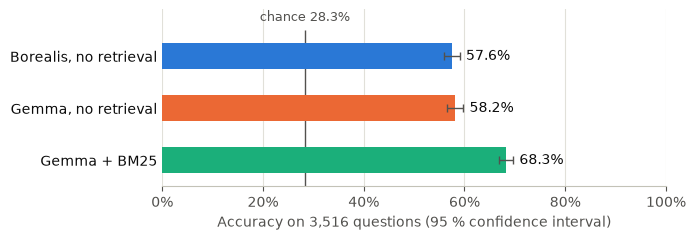

In [22]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

figures = get_path(config, "figures")
figures.mkdir(parents=True, exist_ok=True)

# Figure style, shared by every figure below: one fixed color per condition (slots 1-3 of the colorblind-checked
# reference palette), text in gray-black ink, and quiet hairline grids
COLORS = {borealis_name: "#2a78d6", gemma_plain: "#eb6834", gemma_name: "#1baf7a"}
INK, INK_2, GRID, AXIS = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({"font.size": 10, "text.color": INK, "axes.labelcolor": INK_2, "axes.edgecolor": AXIS,
                     "xtick.color": INK_2, "ytick.color": INK, "savefig.dpi": 300, "savefig.bbox": "tight"})

# Figure 1: accuracy per condition with 95 % confidence intervals, and the chance level
shown = accuracy_table.set_index("condition").loc[list(qa)]
chance = accuracy_table.set_index("condition").loc["Chance (guessing)", "accuracy"]
fig, ax = plt.subplots(figsize=(6.5, 2.3))
rows = range(len(shown))
ax.barh(rows, shown.accuracy, height=0.5, color=[COLORS[name] for name in shown.index], zorder=2)
ax.errorbar(shown.accuracy, rows, xerr=[shown.accuracy - shown.ci_low, shown.ci_high - shown.accuracy],
            fmt="none", ecolor=INK_2, elinewidth=1, capsize=3, zorder=3)
for row, (name, values) in zip(rows, shown.iterrows()):  # the value just past the end of the interval
    ax.text(values.ci_high + 0.012, row, f"{values.accuracy:.1%}", va="center", color=INK)
ax.vlines(chance, -0.5, len(shown) - 0.5, color=INK_2, linewidth=1, zorder=1)  # stops below its label
ax.text(chance, -0.62, f"chance {chance:.1%}", ha="center", va="bottom", color=INK_2, fontsize=9)
ax.set_yticks(list(rows), shown.index)
ax.set_ylim(len(shown) - 0.5, -0.9)  # first condition on top, room for the chance label
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlabel(f"Accuracy on {len(questions):,} questions (95 % confidence interval)")
ax.grid(axis="x", color=GRID, linewidth=0.8, zorder=0)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
fig.savefig(figures / "accuracy.png")
plt.show()

## 5 · Error breakdown

Where the gain from retrieval comes from. Each question is split by whether the chosen retriever put a relevant chunk in the top 5 (judge labels) and whether the answer was right. The same split for the two conditions without retrieval shows whether the questions with a relevant chunk are simply easier. "Fixed" and "broken" compare Gemma with and without retrieval on the same question.

In [23]:
from norrag.metrics import error_breakdown

hits = scores["judge"][scores["judge"].retriever == chosen]  # hit@k per question for the chosen retriever
breakdown = error_breakdown(qa[gemma_name], hits)
breakdown.to_csv(tables / "error_breakdown.csv")
breakdown.round(3)

answer,right,wrong,accuracy
retrieval,,,
relevant chunk in top k,1258,34,0.974
no relevant chunk,1142,1082,0.513


In [24]:
# The same split for all three conditions: if the models without retrieval also do better on the questions
# where the retriever found a relevant chunk, those questions are partly just easier
accuracy_by_hit = pd.DataFrame({name: error_breakdown(results, hits)["accuracy"] for name, results in qa.items()})
accuracy_by_hit["questions"] = breakdown["right"] + breakdown["wrong"]
accuracy_by_hit.to_csv(tables / "accuracy_by_retrieval_hit.csv")
accuracy_by_hit.round(3)

,"Borealis, no retrieval","Gemma, no retrieval",Gemma + BM25,questions
retrieval,,,,
relevant chunk in top k,0.650,0.646,0.974,1292
no relevant chunk,0.533,0.545,0.513,2224


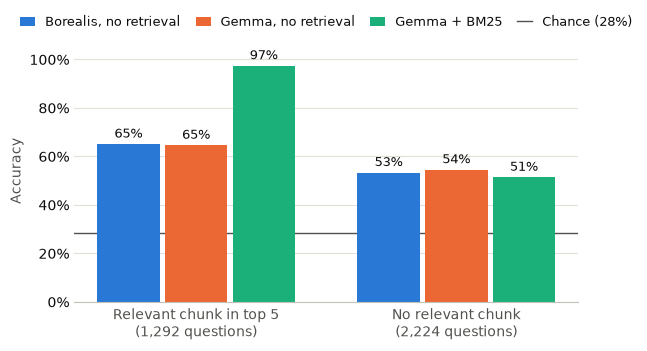

In [25]:
# Figure 2: accuracy with and without a relevant chunk in the chosen retriever's top k, for all three conditions
groups = [f"Relevant chunk in top {k}\n({accuracy_by_hit.questions.iloc[0]:,} questions)",
          f"No relevant chunk\n({accuracy_by_hit.questions.iloc[1]:,} questions)"]
fig, ax = plt.subplots(figsize=(6.5, 3.4))
width = 0.24  # each column; the step between columns is a little wider, leaving a thin gap
for position, name in enumerate(qa):
    xs = [group + (position - 1) * (width + 0.02) for group in range(len(groups))]
    values = accuracy_by_hit[name]
    ax.bar(xs, values, width=width, color=COLORS[name], label=name, zorder=2)
    for x, value in zip(xs, values):  # the value on top of each column
        ax.text(x, value + 0.015, f"{value:.0%}", ha="center", va="bottom", color=INK, fontsize=9)
ax.axhline(chance, color=INK_2, linewidth=1, zorder=1, label=f"Chance ({chance:.0%})")
ax.set_xticks(range(len(groups)), groups)
ax.set_ylim(0, 1.08)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_ylabel("Accuracy")
ax.grid(axis="y", color=GRID, linewidth=0.8, zorder=0)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="both", length=0)
handles, labels = ax.get_legend_handles_labels()  # matplotlib lists the line first; put it last
order = [labels.index(name) for name in qa] + [labels.index(f"Chance ({chance:.0%})")]
ax.legend([handles[i] for i in order], [labels[i] for i in order], loc="lower center", bbox_to_anchor=(0.5, 1.0),
          ncol=4, frameon=False, fontsize=9, handlelength=1.2, columnspacing=1.2)
fig.savefig(figures / "accuracy_by_retrieval_hit.png")
plt.show()

In [26]:
# Gemma with and without retrieval on the same question: fixed = wrong without, right with; broken = the opposite
change = by_question[gemma_name] - by_question[gemma_plain]  # +1 fixed, -1 broken, 0 unchanged
hit_by_question = hits.set_index("qid").hit
retrieval = hit_by_question.map({1.0: "relevant chunk in top k", 0.0: "no relevant chunk"}).rename("retrieval")
fixed_broken = (pd.DataFrame({"fixed": change == 1, "broken": change == -1})
                  .groupby(retrieval).sum()
                  .reindex(["relevant chunk in top k", "no relevant chunk"]))
fixed_broken.loc["all questions"] = fixed_broken.sum()
fixed_broken["net"] = fixed_broken["fixed"] - fixed_broken["broken"]
fixed_broken.to_csv(tables / "fixed_broken.csv")
fixed_broken

,fixed,broken,net
retrieval,,,
relevant chunk in top k,434,10,424
no relevant chunk,266,335,-69
all questions,700,345,355


In [27]:
# The questions where Gemma with retrieval put less than half its probability on the letters (section 3)
gemma_rag = qa[gemma_name].set_index("qid")
low_mass = gemma_rag.logprobs.apply(letter_mass) < 0.5
low = pd.DataFrame({"hit": hit_by_question, "correct": gemma_rag.correct})[low_mass]
print(f"{len(low)} questions with letter mass below 50 %: {int(low.hit.sum())} with a relevant chunk in the top {k}, "
      f"{int(low.correct.sum())} answered right ({low.correct.mean():.0%}; all questions: {gemma_rag.correct.mean():.0%})")

98 questions with letter mass below 50 %: 1 with a relevant chunk in the top 5, 25 answered right (26%; all questions: 68%)
